In [1]:
import osmnx as ox
import pyrosm

In [2]:
fp = "chile-latest.osm.pbf"
place_name = "Concepción, Chile"

place_string = "_".join(place_name.lower().split(",")[0].split(" "))

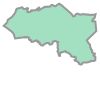

In [3]:
area_gdf = ox.geocode_to_gdf(place_name)
area = area_gdf.geometry.iloc[0]
area

In [5]:
bbox_concepcion = area.bounds
[*bbox_concepcion]

[-73.0915891, -36.9268099, -72.8446184, -36.7644238]

In [20]:
osm = pyrosm.OSM(fp, bounding_box=[*bbox_concepcion], engine="out_of_core")
osm.to_pbf("concepcion.osm.pbf")

Cropping chile-latest.osm.pbf:   0%|          | 0.00/350M [00:00<?, ?B/s]

'concepcion.osm.pbf'

In [ ]:
osm = pyrosm.OSM(fp, bounding_box=[*bbox_concepcion], engine="out_of_core")
nodes, edges = osm.get_network("drive", nodes=True)

,lon,lat,tags,visible,version,timestamp,changeset,id,geometry
0,-73.030689,-36.814561,None,True,76,1742331558,0,267548301,POINT (-73.03069 -36.81456)
1,-73.030626,-36.814508,"{'crossing': 'traffic_signals', 'highway': 'cr...",True,2,1742331558,0,11115686725,POINT (-73.03063 -36.81451)
2,-73.030538,-36.814412,None,True,1,1742331558,0,12677463345,POINT (-73.03054 -36.81441)
3,-73.030162,-36.814001,None,True,7,1742331558,0,5695201203,POINT (-73.03016 -36.814)
4,-73.075205,-36.844536,None,True,4,1655361038,0,7129466229,POINT (-73.0752 -36.84454)
...,...,...,...,...,...,...,...,...,...
64318,-73.049136,-36.794451,None,True,1,1651632146,0,9712830265,POINT (-73.04914 -36.79445)
64319,-73.087776,-36.777187,{'traffic_calming': 'hump'},True,2,1653345587,0,9756079880,POINT (-73.08778 -36.77719)
64320,-73.087838,-36.778322,None,True,1,1659480232,0,9928191563,POINT (-73.08784 -36.77832)
64321,-73.087833,-36.778368,"{'crossing': 'uncontrolled', 'crossing:marking...",True,3,1714832230,0,9756079878,POINT (-73.08783 -36.77837)


---

In [7]:
from pyrosm import OSM
import pandas as pd
import networkx as nx
from shapely.geometry import LineString

# 1. Load the network from your PBF file
osm_file = "concepcion.osm.pbf"
osm = OSM(osm_file)
nodes, edges = osm.get_network(network_type="driving", nodes=True)

# 2. Build a NetworkX directed graph from the edges
# Ensure 'u' (source) and 'v' (target) columns exist
print("Analyzing network topology...")
G = nx.from_pandas_edgelist(
    edges, source='u', target='v', 
    edge_attr=True, create_using=nx.MultiDiGraph()
)

# 3. Find "trapped" dead-end nodes: 
# Nodes that have incoming traffic (in_degree > 0) but NO outgoing traffic (out_degree == 0)
trapped_nodes = {n for n, out_deg in G.out_degree() if out_deg == 0 and G.in_degree(n) > 0}
print(f"Found {len(trapped_nodes)} dead-end / trapped nodes in the network.")

# 4. Filter the edges that lead into these dead-end nodes
dead_end_edges = edges[edges['v'].isin(trapped_nodes)].copy()

# 5. Create the reversed (escape) duplicates for those edges
reversed_edges = dead_end_edges.copy()

# Reverse the geometry coordinates so the line points backward
reversed_edges['geometry'] = reversed_edges['geometry'].apply(
    lambda geom: LineString(list(geom.coords)[::-1])
)

# Swap the start (u) and end (v) routing nodes
temp_u = reversed_edges['u'].copy()
reversed_edges['u'] = reversed_edges['v']
reversed_edges['v'] = temp_u

# Force both original and reversed edges to be open, two-way roads
dead_end_edges['oneway'] = 'no'
reversed_edges['oneway'] = 'no'
dead_end_edges['access'] = 'yes'
reversed_edges['access'] = 'yes'

# 6. Reconstruct the full edge table: unaffected edges + patched dead ends + new escape paths
edges_patched = pd.concat(
    [edges.drop(index=dead_end_edges.index), dead_end_edges, reversed_edges], 
    ignore_index=True
)

# 7. Write the patched network out to a new PBF file
output_pbf = "concepcion_bidirectional.osm.pbf"
# osm.to_pbf(edges_patched, output_pbf)
osm.write_pbf(edges_patched, output_pbf, subset_only=True)

print(f"Successfully generated patched network: {output_pbf}")

Analyzing network topology...
Found 1728 dead-end / trapped nodes in the network.
Successfully generated patched network: concepcion_bidirectional.osm.pbf


In [26]:
G.nodes()

NodeView((267548301, 11115686725, 12677463345, 5695201203, 7129466229, 359565487, 7129466234, 7129466237, 7129466241, 4053275491, 7129466240, 7129466242, 303526691, 359565495, 380417551, 10961084172, 10961084171, 5616641687, 4758760114, 5616641691, 11013330747, 303526686, 359565505, 11013330748, 380411290, 6611197872, 11013330749, 11013330738, 4758763721, 7137859976, 11013330752, 4758760120, 11013330751, 303526683, 11013330750, 6611197873, 11013330753, 6611197878, 6167288951, 11013330754, 14063103614, 11013330755, 303526680, 303482252, 4854822119, 4854822118, 4854822117, 303488396, 4854822116, 4854822115, 4854822114, 4854822113, 303488400, 4854822112, 4854822111, 4854822110, 4854822109, 4854822108, 4854822107, 4854822106, 4854822105, 4854822104, 4854822103, 4854822102, 4854822101, 4854822100, 4854822099, 4854822098, 303488388, 4854822097, 4854822096, 4854822095, 4854822094, 4854822093, 4854822092, 4854822091, 4854822090, 303488392, 4854822089, 4854822088, 4854822087, 4854822086, 485482

In [ ]:
ox.nearest_nodes(G, central_lon, central_lat)

KeyError: 'crs'

In [28]:
import pyrosm
from pyrosm import OSM
import pandas as pd
import networkx as nx
from shapely.geometry import LineString

# 1. Load the network
osm_file = "concepcion.osm.pbf"
osm = OSM(osm_file)
nodes, edges = osm.get_network(network_type="driving", nodes=True)

nodes = nodes.rename(columns={'lon': 'x', 'lat': 'y'})

# 2. Build the directed NetworkX graph
G = osm.to_graph(nodes, edges, graph_type="networkx", simplify=True)

print("Analyzing network topology...")

# 3. Define a central node (e.g., using coordinates of a major downtown plaza or hub)
# For example, let's find the graph node closest to central Concepción coordinates (lon, lat)
central_lon, central_lat = -73.050, -36.827  # Adjust to your city center
# Find the closest node in G (using pyrosm/spatial lookup or networkx node coordinates if available)
# Alternatively, you can pick a known node ID directly if you have one.
# For demonstration, let's find the node with the minimum distance or pick a node programmatically:
central_node = ox.nearest_nodes(G, central_lon, central_lat)
print(f"Selected central target node ID: {central_node}")

# 4. Find all nodes that CAN reach this central node
valid_ancestors = nx.ancestors(G, central_node)
valid_ancestors.add(central_node) # Include the center itself

# 5. Identify unreachable nodes (nodes that have NO route to the center)
unreachable_nodes = set(G.nodes) - valid_ancestors
print(f"Found {len(unreachable_nodes)} nodes disconnected from the center.")

# 6. Filter edges connected to these unreachable pockets
unreachable_edges = edges[
    edges['u'].isin(unreachable_nodes) | edges['v'].isin(unreachable_nodes)
].copy()

# 7. Create the reversed (escape) duplicates for those edges so they can flow both ways
reversed_edges = unreachable_edges.copy()
reversed_edges['geometry'] = reversed_edges['geometry'].apply(
    lambda geom: LineString(list(geom.coords)[::-1])
)

temp_u = reversed_edges['u'].copy()
reversed_edges['u'] = reversed_edges['v']
reversed_edges['v'] = temp_u

# Force two-way open access on these segments
unreachable_edges['oneway'] = 'no'
reversed_edges['oneway'] = 'no'
unreachable_edges['access'] = 'yes'
reversed_edges['access'] = 'yes'

# 8. Reconstruct the patched edge table
edges_patched = pd.concat(
    [edges.drop(index=unreachable_edges.index), unreachable_edges, reversed_edges], 
    ignore_index=True
)

# 9. Write out to the new PBF file
output_pbf = "concepcion_connected.osm.pbf"
osm.write_pbf(edges_patched, output_pbf, subset_only=True)

print(f"Successfully generated fully connected network: {output_pbf}")

Analyzing network topology...
Selected central target node ID: 1271161974
Found 0 nodes disconnected from the center.
Successfully generated fully connected network: concepcion_connected.osm.pbf
